# <a href="https://girafe.ai/" target="_blank" rel="noopener noreferrer"><img src="https://raw.githubusercontent.com/girafe-ai/ml-course/7096a5df4cada5ee651be1e3215c2f7fb8a7e0bf/logo_margin.svg" alt="girafe-ai logo" width="150px" align="left"></a> [ml-basic course](https://github.com/girafe-ai/ml-course) <a class="tocSkip">


# Lab assignment 01
## Data preprocessing, model training and evaluation

This lab assignment consists of several parts.

In this part you are supposed to work with tabular data: make some transformations, train some models, estimate the quality of the models and explain your results.

Several comments:
* Don't hesitate to ask questions in a chat, it's a good practice.
* No private/public sharing, please. The copied assignments will be graded with 0 points.
* Blocks of this lab will be graded separately.

## 1. Reading the data
Today we work with the [dataset](https://archive.ics.uci.edu/ml/datasets/Statlog+%28Vehicle+Silhouettes%29), describing different cars for multiclass ($k=4$) classification problem. The data is available below.

In [429]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [430]:
import ucimlrepo as uci
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy

from sklearn.model_selection import train_test_split

In [431]:
dataset = uci.fetch_ucirepo(id=149)

print(dataset.metadata.name, '\n')
print(dataset.metadata.abstract, '\n')
print(dataset.metadata.additional_info.summary, '\n')

Statlog (Vehicle Silhouettes) 

3D objects within a 2D image by application of an ensemble of shape feature extractors to the 2D silhouettes of the objects. 

The purpose is to classify a given silhouette as one of four types of vehicle, using  a set of features extracted from the silhouette. The vehicle may be viewed from one of many different angles.  

HISTORY:

This data was originally gathered at the TI in 1986-87 by JP Siebert. It was partially financed by Barr and Stroud Ltd. The original purpose was to find a method of distinguishing 3D objects within a 2D image by application of an ensemble of shape feature extractors to the 2D silhouettes of the objects. Measures of shape features extracted from example silhouettes of objects to be discriminated were used to generate a classification rule tree by means of computer induction.

This object recognition strategy was successfully used to discriminate between silhouettes of model cars, vans and buses viewed from constrained elevati

In [432]:
data = dataset.data.features
target = dataset.data.targets

print(data.shape, target.shape)

(846, 18) (846, 1)


### 1.1 Data integrity

Check if data is valid. If it is not, remove invalid parts.


In [433]:
# берем признаки и таргет из датасета
feature_df = dataset.data.features.copy()
target_df = dataset.data.targets.copy()

# склеиваем в один датафрейм
df = pd.concat([feature_df, target_df], axis=1)
print("Shape before cleaning:", df.shape)

# заменяем бесконечности на NaN
df = df.replace([np.inf, -np.inf], np.nan)

# смотрим где NaN и сколько их (сумма)
print("NaNs per column:",)
print(df.isna().sum())

# удаляем строки в которых есть NaN
df = df.dropna()

# удаляем дубликаты строк
df = df.drop_duplicates()

print("Shape after cleaning:", df.shape)

# финальные данные после очистки (копии для избежания предупреждений)
feature_df = df[feature_df.columns].copy()
target_df = df[target_df.columns].copy() 

Shape before cleaning: (846, 19)
NaNs per column:
COMPACTNESS                         1
CIRCULARITY                         0
DISTANCE CIRCULARITY                0
RADIUS RATIO                        0
PR.AXIS ASPECT RATIO                0
MAX.LENGTH ASPECT RATIO             0
SCATTER RATIO                       0
ELONGATEDNESS                       0
PR.AXIS RECTANGULARITY              0
MAX.LENGTH RECTANGULARITY           0
SCALED VARIANCE ALONG MAJOR AXIS    0
SCALED VARIANCE ALONG MINOR AXIS    0
SCALED RADIUS OF GYRATION           0
SKEWNESS ABOUT MAJOR AXIS           0
SKEWNESS ABOUT MINOR AXIS           0
KURTOSIS ABOUT MINOR AXIS           0
KURTOSIS ABOUT MAJOR AXIS           0
HOLLOWS RATIO                       0
class                               0
dtype: int64
Shape after cleaning: (845, 19)


in "COMPACTNESS" found Nan and remove it

### 1.2 Train and test sets

Split data into 2 groups using `sklearn`'s infrastructure.

Which size of test set to choose?

In [434]:
X = feature_df
y = target_df['class'] # one-dimensional array

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,
    test_size=0.2, 
    random_state=42,
    stratify=y # save class proportions
)

In [435]:
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(676, 18) (676,) (169, 18) (169,)


To get some insights about the dataset, `pandas` might be used. The `train` part is transformed to `pd.DataFrame` below.

In [436]:
X_train_pd = pd.DataFrame(X_train)

# First 15 rows of our dataset.
X_train_pd.head(15)

,COMPACTNESS,CIRCULARITY,DISTANCE CIRCULARITY,RADIUS RATIO,PR.AXIS ASPECT RATIO,MAX.LENGTH ASPECT RATIO,SCATTER RATIO,ELONGATEDNESS,PR.AXIS RECTANGULARITY,MAX.LENGTH RECTANGULARITY,SCALED VARIANCE ALONG MAJOR AXIS,SCALED VARIANCE ALONG MINOR AXIS,SCALED RADIUS OF GYRATION,SKEWNESS ABOUT MAJOR AXIS,SKEWNESS ABOUT MINOR AXIS,KURTOSIS ABOUT MINOR AXIS,KURTOSIS ABOUT MAJOR AXIS,HOLLOWS RATIO
200,93.0,47,85,163,66,11,156,44,20,158,172,355,178,74,7,15,183,195
396,108.0,57,106,177,51,5,256,26,28,170,285,966,261,87,11,2,182,181
309,109.0,48,107,215,62,10,205,32,23,158,222,624,168,65,9,32,195,206
86,89.0,41,84,141,58,9,149,45,19,145,172,330,162,72,4,18,188,200
635,97.0,41,62,133,56,7,130,52,18,143,158,247,157,78,5,7,184,186
246,95.0,36,73,191,73,6,156,41,19,126,184,374,124,71,2,19,199,204
782,87.0,44,98,211,70,10,189,35,22,141,214,535,178,71,2,21,187,194
539,109.0,55,96,191,57,6,241,28,26,170,267,857,242,85,8,9,184,184
698,83.0,42,71,152,64,7,149,45,19,142,172,331,158,74,2,2,184,190
794,87.0,41,76,165,67,7,148,45,19,140,171,327,152,72,7,13,188,195


Methods `describe` and `info` deliver some useful information.

In [437]:
X_train_pd.describe()

,COMPACTNESS,CIRCULARITY,DISTANCE CIRCULARITY,RADIUS RATIO,PR.AXIS ASPECT RATIO,MAX.LENGTH ASPECT RATIO,SCATTER RATIO,ELONGATEDNESS,PR.AXIS RECTANGULARITY,MAX.LENGTH RECTANGULARITY,SCALED VARIANCE ALONG MAJOR AXIS,SCALED VARIANCE ALONG MINOR AXIS,SCALED RADIUS OF GYRATION,SKEWNESS ABOUT MAJOR AXIS,SKEWNESS ABOUT MINOR AXIS,KURTOSIS ABOUT MINOR AXIS,KURTOSIS ABOUT MAJOR AXIS,HOLLOWS RATIO
count,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000,676.000000
mean,93.353550,44.788462,81.789941,168.440828,61.741124,8.693787,168.115385,41.106509,20.526627,147.902367,188.020710,435.831361,174.437870,72.576923,6.322485,12.321006,188.809172,195.534024
std,8.214937,6.119156,15.678160,33.935814,8.345653,5.024623,32.876717,7.760520,2.568908,14.480411,30.910904,174.266015,32.083742,7.707140,4.872857,8.982893,6.168064,7.425304
min,73.000000,33.000000,40.000000,104.000000,47.000000,3.000000,112.000000,26.000000,17.000000,118.000000,130.000000,184.000000,112.000000,59.000000,0.000000,0.000000,176.000000,181.000000
25%,87.000000,40.000000,70.000000,140.000000,57.000000,7.000000,146.000000,33.000000,19.000000,137.000000,167.000000,317.000000,150.000000,68.000000,2.000000,5.000000,184.000000,190.750000
50%,92.000000,44.000000,79.000000,166.000000,61.000000,8.000000,156.000000,43.000000,19.000000,146.000000,177.500000,360.500000,173.000000,72.000000,6.000000,11.000000,188.000000,197.000000
75%,99.000000,49.000000,96.500000,194.000000,65.000000,10.000000,197.000000,46.000000,23.000000,159.000000,217.000000,583.250000,198.000000,76.000000,9.000000,18.000000,193.000000,201.000000
max,119.000000,59.000000,112.000000,333.000000,138.000000,55.000000,265.000000,61.000000,29.000000,186.000000,320.000000,1018.000000,268.000000,135.000000,22.000000,41.000000,206.000000,211.000000


In [438]:
X_train_pd.info()

<class 'pandas.core.frame.DataFrame'>
Index: 676 entries, 200 to 656
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   COMPACTNESS                       676 non-null    float64
 1   CIRCULARITY                       676 non-null    int64  
 2   DISTANCE CIRCULARITY              676 non-null    int64  
 3   RADIUS RATIO                      676 non-null    int64  
 4   PR.AXIS ASPECT RATIO              676 non-null    int64  
 5   MAX.LENGTH ASPECT RATIO           676 non-null    int64  
 6   SCATTER RATIO                     676 non-null    int64  
 7   ELONGATEDNESS                     676 non-null    int64  
 8   PR.AXIS RECTANGULARITY            676 non-null    int64  
 9   MAX.LENGTH RECTANGULARITY         676 non-null    int64  
 10  SCALED VARIANCE ALONG MAJOR AXIS  676 non-null    int64  
 11  SCALED VARIANCE ALONG MINOR AXIS  676 non-null    int64  
 12  SCALED RADI

## 2. Machine Learning pipeline
Here you are supposed to perform the desired transformations. Please, explain your results briefly after each task.

### 2.0. Data preprocessing

Apply transformations to the dataset (if necessary).

Briefly explain the transformations

In [439]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(X_train) # fit only on train data to avoid data leakage
X_train_scaled = scaler.transform(X_train) 
X_test_scaled = scaler.transform(X_test)

# save the dataframes structure
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

Since the data has already been cleared of NaN and categorical variables are missing, as we saw in the previous steps, the main step of preprocessing is scaling.   

   The scaler.fit step is applicable only to the train sample, because if we apply it to the full dataset, data leakage will occur and information about the test sample will leak into the pipeline.


### 2.1. Basic logistic regression

* Find optimal hyperparameters for logistic regression with cross-validation on the `train` data (small grid/random search is enough, no need to find the *best* parameters).

* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression:\
`multi_class='multinomial'`, `solver='saga'` `tol=1e-3` and ` max_iter=500`.*

In [440]:

from sklearn.linear_model import LogisticRegression

In [441]:
MyLogReg = LogisticRegression(
    tol=1e-3, 
    solver='saga', 
    max_iter=500,  
    multi_class='multinomial', 
    random_state=42
)

MyLogReg.fit(X_train_scaled, y_train)

c:\Users\pc\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


,penalty,'l2'
,dual,False
,tol,0.001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'saga'
,max_iter,500
,multi_class,'multinomial'


In [442]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    estimator=MyLogReg,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,
)

# grid will train the required number of copies of the MyLogReg model by itself
grid.fit(X_train_scaled, y_train) 

print(grid.best_params_) 

print(grid.best_score_) # the best mean cross-validated score

best_logreg = grid.best_estimator_ # model with the best parameters 

{'C': 10}
0.7910693371887623


c:\Users\pc\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [443]:
from sklearn.metrics import accuracy_score, f1_score

y_pred = best_logreg.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", acc)
print("F1-macro:", f1)  

accuracy: 0.8402366863905325
F1-macro: 0.8371524841260252


In [444]:
%pip install scikit-plot


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


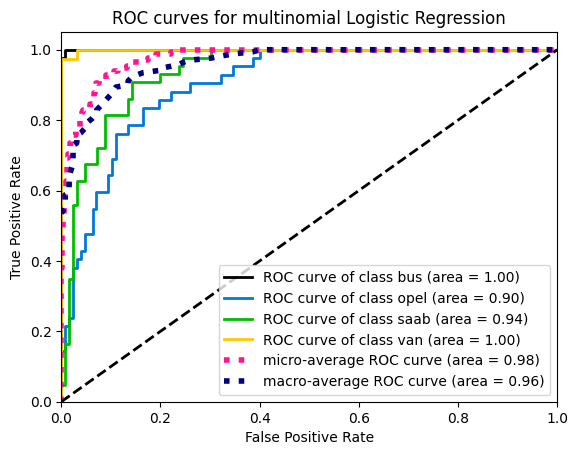

In [445]:

# добавляем в scipy недостающую функцию interp
scipy.interp = np.interp

import scikitplot as skplt


y_proba = best_logreg.predict_proba(X_test_scaled)

skplt.metrics.plot_roc(y_test, y_proba)
plt.title("ROC curves for multinomial Logistic Regression")
plt.show()

The ROC curves show that the multinomial logistic regression model does a good job of this task.
For bus and van classes, the ROC curves (black and yellow) are almost perfectly aligned with the upper-left corner, which means that the model can almost perfectly separate these classes from others.   

For two car classes (opel and saab), the ROC curves are slightly lower, with AUC values of 0.90 and 0.94, respectively. This corresponds to the description from the information about the dataset: the silhouettes of the two cars are much more similar to each other, so it is more difficult for the classifier to distinguish them, which leads to a greater coincidence and a decrease in the percentage of true predictions.     

The dotted diagonal black line corresponds to a random classifier (AUC = 0.5). All ROC curves belonging to a particular class lie well above this baseline, which confirms that the model recognizes a meaningful data structure.    

micro-average AUC ≈ 0.98 - we take all classes without separation and calculate the TP-FP metrics for all predictions and build a ROC curve
macro-average AUC ≈ 0.96 - for each class, we calculate its metrics and then simply average them over all classes (each class gives the same class), it is just noticeable that there are classes that reduce the average quality

### 2.2. PCA: explained variance plot

Apply the PCA to the train part of the data.

Build the explaided variance plot.

In [446]:
from sklearn.decomposition import PCA
MyPCA = PCA(n_components=X_train_scaled.shape[1])  
MyPCA.fit(X_train_scaled)

,n_components,18
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


Let's take all the available signs to begin with.

In [447]:
explained_var = MyPCA.explained_variance_ratio_ # the proportion of variance of each component
cum_explained_var = np.cumsum(explained_var)   

for i, v in enumerate(np.cumsum(MyPCA.explained_variance_ratio_), start=1):
    print(i, v)

1 0.5233807999672248
2 0.6871054891421287
3 0.7990859499809903
4 0.865386690463728
5 0.9150334474385577
6 0.9438320386456582
7 0.9630866939187669
8 0.9750638881960131
9 0.9836733380574716
10 0.9888171863384463
11 0.9925107780969672
12 0.9949978056905301
13 0.9969409385639916
14 0.9981044325563652
15 0.9989294977011601
16 0.9996235972810714
17 0.9999793329744341
18 0.9999999999999999


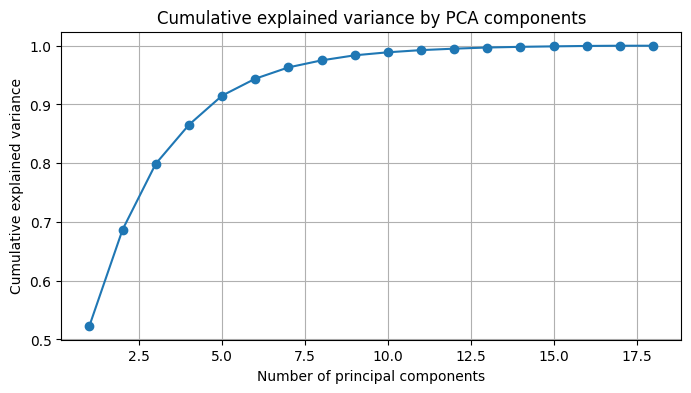

In [448]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_explained_var) + 1), cum_explained_var, marker='o')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance')
plt.grid(True)
plt.title('Cumulative explained variance by PCA components')
plt.show()


The PCA graph shows that the cumulative explained variance grows rapidly and then begins to increase. From about 5-7 main components, we already get more than 90% of the total variance, while each of the other components contributes only a very small fraction.  

In many practical applications, it is considered sufficient to preserve about 90-95% of the variance: additional components already simulate noise and add complexity, without giving a proportional increase in the amount of information.

Therefore, in the next step, we will reduce the dimension from 18 initial objects to a smaller number of main components, for example, to 5, which will preserve most of the information about the data, while simplifying the model and improving its generalization.

### 2.3. PCA trasformation

Select the appropriate number of components.

Briefly explain your choice. Should you normalize the data?

*Use `fit` and `transform` methods to transform the `train`, `val` and `test` parts.*

We have significantly reduced the number of features (from 18 to 7), while retaining most of the data variability.

In [449]:
n_components_min = 7
MyPCA_n = PCA(n_components=n_components_min)  
MyPCA_n.fit(X_train_scaled)

,n_components,7
,copy,True
,whiten,False
,svd_solver,'auto'
,tol,0.0
,iterated_power,'auto'
,n_oversamples,10
,power_iteration_normalizer,'auto'
,random_state,None


Reducing the number of signs. Each new feature is a linear combination of the old ones.;

In [450]:
X_train_pca = MyPCA_n.transform(X_train_scaled)
X_test_pca = MyPCA_n.transform(X_test_scaled)

print(X_train_pca.shape, X_test_pca.shape)

(676, 7) (169, 7)


PCA is sensitive to the scale of objects, so the data must be standardized before applying PCA. In this experiment, PCA is compared with standardized training data (X_train_scaled), and the same scaling is applied to the test data.

In [451]:
print(np.cumsum(MyPCA_n.explained_variance_ratio_)[-1])

0.9630866939187669


The last element of the cumulative sum array - the sum of all components - is greater than 0.9, which means that there are enough features.

Note: From this point `sklearn` [Pipeline](https://scikit-learn.org/stable/modules/compose.html) might be useful to perform transformations on the data. Refer to the [docs](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) for more information.

### 2.4. Logistic regression on PCA-preprocessed data

* Find optimal hyperparameters for logistic regression with cross-validation on the transformed by PCA `train` data.
* Estimate the model quality with `f1` and `accuracy` scores.
* Plot a ROC-curve for the trained model. For the multiclass case you might use `scikitplot` library (e.g. `scikitplot.metrics.plot_roc(test_labels, predicted_proba)`).

*Note: please, use the following hyperparameters for logistic regression:\
`multi_class='multinomial'`, `solver='saga'` and `tol=1e-3`*

In [452]:
MyLogReg_PCA = LogisticRegression(
    tol=1e-3, 
    solver='saga', 
    max_iter=500,  
    multi_class='multinomial', 
    random_state=42
)

In [453]:

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    estimator=MyLogReg_PCA,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,
)

grid.fit(X_train_pca, y_train) 

print(grid.best_params_) 
print(grid.best_score_) 

best_logreg = grid.best_estimator_ 


{'C': 10}
0.6243378591251193


c:\Users\pc\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [454]:

y_pred = best_logreg.predict(X_test_pca)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", acc)
print("F1-macro:", f1)  

accuracy: 0.6331360946745562
F1-macro: 0.6302744182387638


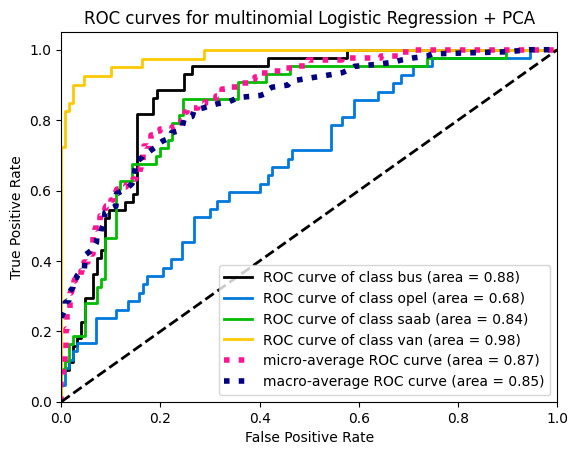

In [455]:
y_proba = best_logreg.predict_proba(X_test_pca)

skplt.metrics.plot_roc(y_test, y_proba)
plt.title("ROC curves for multinomial Logistic Regression + PCA")
plt.show()

After applying PCA with 7 components (which account for about 96% of the total variance), the performance of the logistic regression model deteriorates markedly: the accuracy drops from ~0.84 to ~0.63, and the macro F1 indicator shows a similar decrease.
This illustrates an important limitation of PCA.: it preserves the directions with the greatest variance, but these directions are not necessarily the most distinguishable for the classification task. Low-variance components that have been discarded may still contain information that is crucial for separating the most similar classes (there are two types of cars in this dataset).
Therefore, in this particular task, PCA does not improve the classifier and actually degrades its performance.

In [456]:
from sklearn.pipeline import Pipeline

logreg_pca_pipe = Pipeline([
    ('scaler', StandardScaler()),          
    ('pca', PCA(n_components=n_components_min)),          
    ('model', LogisticRegression(          
        tol=1e-3,
        solver='saga',
        max_iter=500,
        multi_class='multinomial',
        random_state=42
    ))
])

In [457]:
param_grid = {
    'model__C': [0.01, 0.1, 1, 10, 100]   # C относится к шагу 'clf'
}

grid_pipe_pca = GridSearchCV(
    estimator=logreg_pca_pipe,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=5,
    n_jobs=-1,
)

grid_pipe_pca.fit(X_train_pca, y_train)

print("Best params:", grid_pipe_pca.best_params_)
print("Best CV f1_macro:", grid_pipe_pca.best_score_)

Best params: {'model__C': 10}
Best CV f1_macro: 0.621844063720257


c:\Users\pc\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\linear_model\_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


accuracy: 0.6331360946745562
F1-macro: 0.6302744182387638


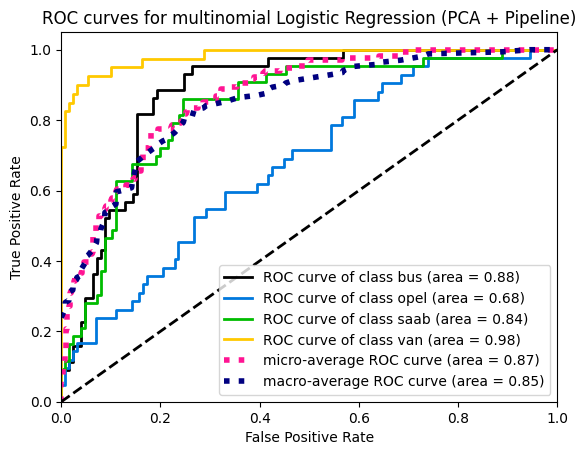

In [458]:
best_pipe = grid_pipe_pca.best_estimator_

y_pred = best_pipe.predict(X_test_pca)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", acc)
print("F1-macro:", f1)

y_proba = best_pipe.predict_proba(X_test_pca)

skplt.metrics.plot_roc(y_test, y_proba)
plt.title("ROC curves for multinomial Logistic Regression (PCA + Pipeline)")
plt.show()


### 2.5. Decision tree

* Now train a desicion tree on the same data. Find optimal tree depth (`max_depth`) using cross-validation.

* Measure the model quality using the same metrics you used above.

In [459]:
from sklearn.tree import DecisionTreeClassifier


tree_pipe = Pipeline([
    ('scaler', StandardScaler()),          
    ('model', DecisionTreeClassifier(
        criterion='gini', 
        max_depth=5,
        random_state=42
    ))
])

In [460]:
param_grid = {
    'model__max_depth': [i for i in range(1, 20)]   
}

grid_pipe_tree = GridSearchCV(
    estimator=tree_pipe,
    param_grid=param_grid,
    scoring='f1_macro',
    n_jobs=-1,
)

grid_pipe_tree.fit(X_train_scaled, y_train)

best_depth = grid_pipe_tree.best_params_['model__max_depth']

print("Best params:", grid_pipe_tree.best_params_)
print("Best CV f1_macro:", grid_pipe_tree.best_score_)

Best params: {'model__max_depth': 10}
Best CV f1_macro: 0.709844808399724


accuracy: 0.6923076923076923
F1-macro: 0.6957044246370089


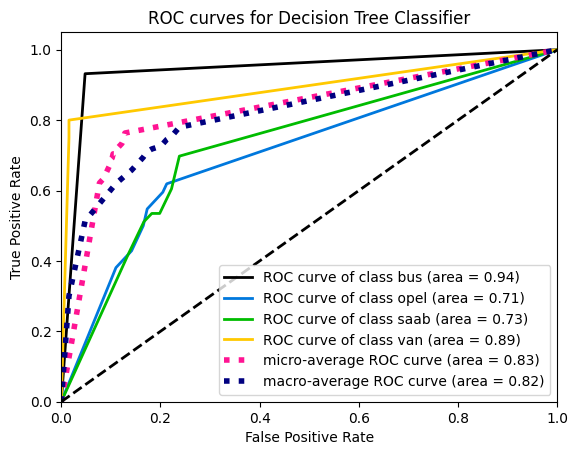

In [461]:
best_pipe = grid_pipe_tree.best_estimator_

y_pred = best_pipe.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", acc)
print("F1-macro:", f1)

y_proba = best_pipe.predict_proba(X_test_scaled)

skplt.metrics.plot_roc(y_test, y_proba)
plt.title("ROC curves for Decision Tree Classifier")
plt.show()


In [462]:
param_grid = {
    'model__max_depth': [i for i in range(2, 25)],
    'model__min_samples_leaf': [1, 2, 5, 10],
    'model__criterion': ['gini', 'entropy', 'log_loss']
}


grid_pipe_tree = GridSearchCV(
    estimator=tree_pipe,
    param_grid=param_grid,
    scoring='f1_macro',
    n_jobs=-1,
)

grid_pipe_tree.fit(X_train_scaled, y_train)

best_depth = grid_pipe_tree.best_params_['model__max_depth']

print("Best params:", grid_pipe_tree.best_params_)
print("Best CV f1_macro:", grid_pipe_tree.best_score_)

Best params: {'model__criterion': 'gini', 'model__max_depth': 9, 'model__min_samples_leaf': 2}
Best CV f1_macro: 0.7125913620798414


accuracy: 0.7159763313609467
F1-macro: 0.7174641167562351


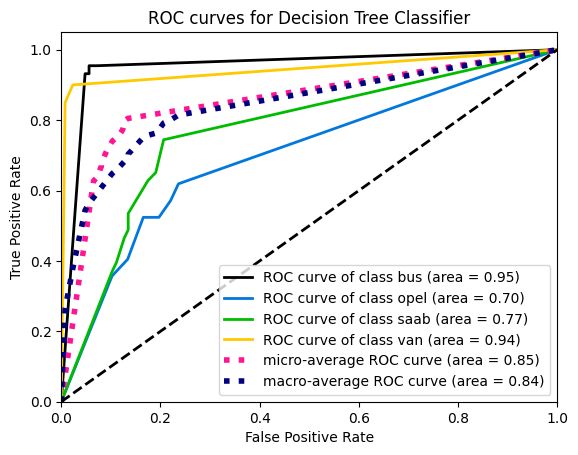

In [463]:
best_pipe = grid_pipe_tree.best_estimator_

y_pred = best_pipe.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", acc)
print("F1-macro:", f1)

y_proba = best_pipe.predict_proba(X_test_scaled)

skplt.metrics.plot_roc(y_test, y_proba)
plt.title("ROC curves for Decision Tree Classifier")
plt.show()


The customized decision tree (`max_depth = 9`, `min_samples_leaf = 2`) provides an accuracy of about 0.72, and the F1 macro provides about 0.72 on the test set, which is still worse than with simple logistic regression without PCA (accuracy 0.84, F1 macro 0.84). This suggests that the class boundaries in this dataset are relatively close to linear, so a linear classifier is a very good fit, while a single decision tree that approximates the boundaries by axis splits cannot use strong non-linearity here and mainly adds variance.

### 2.6. Bagging

Here starts the ensembling part. You need to use [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html)

First we will use the __Bagging__ approach. Build an ensemble of $N$ algorithms varying N from $N_{min}=2$ to $N_{max}=100$ with step 5.

We will build two ensembles: of logistic regressions and of decision trees.

*Comment: each ensemble should be constructed from models of the same family, so logistic regressions should not be mixed up with decision trees.*


*Hint 1: To build a __Bagging__ ensebmle varying the ensemble size efficiently you might generate $N_{max}$ subsets of `train` data (of the same size as the original dataset) using bootstrap procedure once. Then you train a new instance of logistic regression/decision tree with optimal hyperparameters you estimated before on each subset (so you train it from scratch). Finally, to get an ensemble of $N$ models you average the $N$ out of $N_{max}$ models predictions.*

*Hint 2: sklearn might help you with this taks. Some appropriate function/class might be out there.*

* Plot `f1` and `accuracy` scores plots w.r.t. the size of the ensemble.

* Briefly analyse the plot. What is the optimal number of algorithms? Explain your answer.

* How do you think, are the hyperparameters for the decision trees you found in 2.5 optimal for trees used in ensemble?

In [464]:
# YOUR CODE HERE

### 2.7. Random Forest

Now we will work with the [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html).

* Plot `f1` and `accuracy` scores plots w.r.t. the number of trees in Random Forest.

* What is the optimal number of trees you've got? Is it different from the optimal number of logistic regressions/decision trees in 2.6? Explain the results briefly.

In [465]:
from sklearn.ensemble import RandomForestClassifier

# YOUR CODE HERE

### 2.8. Learning curve

Your goal is to estimate, how does the model behaviour change with the increase of the `train` dataset size.

* Split the training data into 10 equal (almost) parts. Then train the models from above (Logistic regression, Desicion Tree, Random Forest) with optimal hyperparameters you have selected. First train it on first part, then on first and second parts combined (so the train size in increased by 2 times), first 3 parts and so on.

* You may use `sklearn`'s [readymade function](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.learning_curve.html). But note that you need to adjust parameters of this function appropriately.

* Build a plot of `accuracy` and `f1` scores on `test` part, varying the `train` dataset size (so the axes will be score vs dataset size).

* Analyse the final plot. Can you make any conlusions using it?

In [466]:
# YOUR CODE HERE

### 2.9. Boosting

Apply [GradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html) to this problem.

Find optimal hyperparameters using [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) or RandomizedSearchCV.

Hyperparameters to consider:
* depth of each tree
* number of decision trees
* learning rate

In [467]:
# YOUR CODE HERE